# 01 · Riesgo climático: pronóstico de temperatura mensual (Ciudad de México)

**Casos de uso:** derivados climáticos (HDD/CDD), métricas de aumento de temperatura en ESG y escenarios para *Climate VaR*.

**Qué hace este notebook**
1. Explora 178 años de temperatura mensual (Berkeley Earth) y mide la **tendencia de calentamiento**.
2. Diagnostica estacionalidad y estacionariedad (FFT, ACF/PACF, ADF + KPSS).
3. Selecciona modelos **ARIMA** y **SARIMA** por AIC usando *solo* datos de entrenamiento.
4. Evalúa el pronóstico fuera de muestra contra un *benchmark* ingenuo estacional (RMSE, MAE, cobertura del intervalo).
5. Traduce la temperatura a **grados-día** (HDD/CDD), el subyacente de los derivados climáticos.

> Adaptación y corrección del enfoque de P. Paialunga (*Towards Data Science*, 2021). Ver `REFERENCES.md`.

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from esg_workshop.plotting import use_style, SERIES, COOL, WARM, MUTED, INK_2

use_style()
pd.set_option("display.precision", 3)
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from esg_workshop import temperature as tp

## 1. Datos

Berkeley Earth, `GlobalLandTemperaturesByMajorCity` — promedio **mensual** en °C y su incertidumbre (IC 95%).
La celda "Mexico" corresponde a la retícula 20.09 N, 98.96 W (región centro, no el punto exacto de la CDMX).

In [2]:
df = tp.load_monthly_temperature()
T = df["avg_temp_c"]
print(f"{T.index.min():%Y-%m} a {T.index.max():%Y-%m} | {len(T)} meses | faltantes: {T.isna().sum()}")
df.tail()

1835-01 a 2013-09 | 2145 meses | faltantes: 0


,avg_temp_c,uncertainty_c
date,,
2013-05-01,19.155,0.317
2013-06-01,18.924,0.252
2013-07-01,18.091,0.558
2013-08-01,17.882,0.481
2013-09-01,18.313,1.231


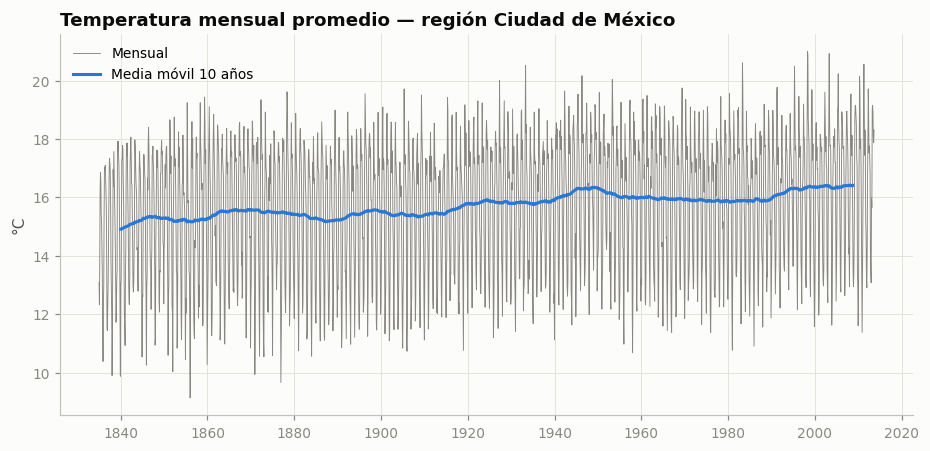

In [3]:
fig, ax = plt.subplots()
ax.plot(T.index, T, color=MUTED, linewidth=0.6, label="Mensual")
ax.plot(T.index, T.rolling(120, center=True).mean(), color=COOL, label="Media móvil 10 años")
ax.set(title="Temperatura mensual promedio — región Ciudad de México", ylabel="°C")
ax.legend(loc="upper left")
plt.show()

## 2. Tendencia de calentamiento

Modelo sobre medias anuales: $\bar T_y = a + b\,y + \varepsilon_y$. La tendencia por década es $10\,b$; el IC usa errores Newey-West (autocorrelación).
Anomalía: diferencia contra el promedio de referencia 1951–1980 (convención de Berkeley Earth).

In [4]:
trends = pd.DataFrame([tp.warming_trend(T), tp.warming_trend(T, start=1951), tp.warming_trend(T, start=1981)])
trends

,period,trend_c_per_decade,ci95_low,ci95_high,p_value,n_years
0,1835-2012,0.071,0.059,0.084,2.961e-28,178
1,1951-2012,0.078,0.036,0.121,3.352e-04,62
2,1981-2012,0.207,0.107,0.306,5.014e-05,32


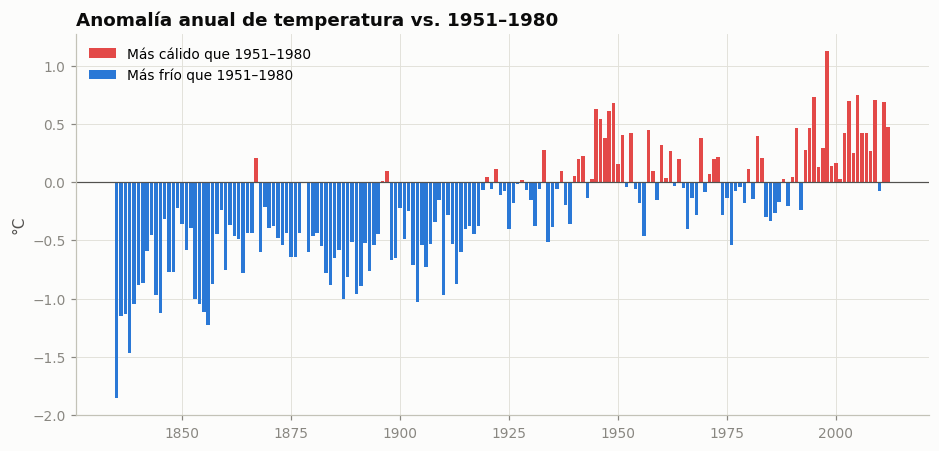

In [5]:
anom = tp.anomaly_vs_baseline(T)
fig, ax = plt.subplots()
ax.bar(anom.index, anom.clip(lower=0), color=WARM, width=0.8, label="Más cálido que 1951–1980")
ax.bar(anom.index, anom.clip(upper=0), color=COOL, width=0.8, label="Más frío que 1951–1980")
ax.axhline(0, color=INK_2, linewidth=0.8)
ax.set(title="Anomalía anual de temperatura vs. 1951–1980", ylabel="°C")
ax.legend(loc="upper left")
plt.show()

## 3. Estacionalidad y estacionariedad

- **FFT (periodograma):** el pico dominante en ~12 meses confirma el ciclo anual.
- **ACF/PACF:** la oscilación con periodo 12 indica que un ARIMA no estacional dejará estructura sin explicar.
- **ADF** ($H_0$: raíz unitaria) y **KPSS** ($H_0$: estacionaria) se leen juntos: si ADF rechaza y KPSS también, la serie tiene tendencia/cambios de nivel, típico de un clima que se calienta.

In [6]:
tp.dominant_periods(T)

,period_months,amplitude_c
0,11.983,2.613
1,12.051,0.850
2,6.008,0.554


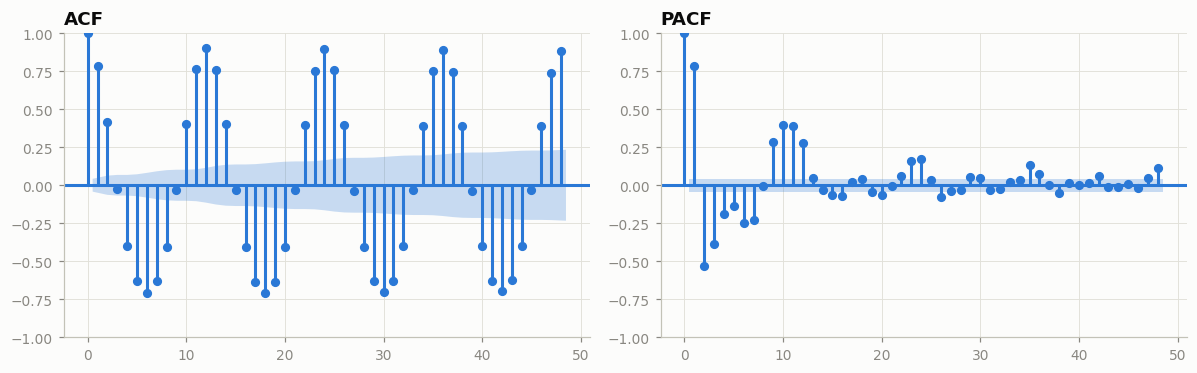

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
plot_acf(T, lags=48, ax=axes[0], color=COOL, vlines_kwargs={"colors": COOL})
plot_pacf(T, lags=48, ax=axes[1], color=COOL, vlines_kwargs={"colors": COOL}, method="ywm")
axes[0].set_title("ACF"); axes[1].set_title("PACF")
plt.tight_layout(); plt.show()

In [8]:
pd.DataFrame({"1835–2013": tp.stationarity_report(T), "1992–2013": tp.stationarity_report(T["1992":])})

,1835–2013,1992–2013
n_obs,2145.000,261.000
adf_stat,-4.009,-3.527
adf_p,0.001,0.007
kpss_stat,3.246,0.038
kpss_p,0.010,0.100


## 4. Modelado: ARIMA vs SARIMA

Muestra de modelado 1992–2013. **Separación cronológica**: los últimos 24 meses son prueba y nunca se usan para elegir el modelo.

$$\text{SARIMA}(p,d,q)(P,D,Q)_{12}:\quad \phi(L)\,\Phi(L^{12})\,(1-L)^d(1-L^{12})^D\,T_t = \theta(L)\,\Theta(L^{12})\,\varepsilon_t$$

Entrenamiento: 1992-01 a 2011-09 (237) | Prueba: 2011-10 a 2013-09 (24)


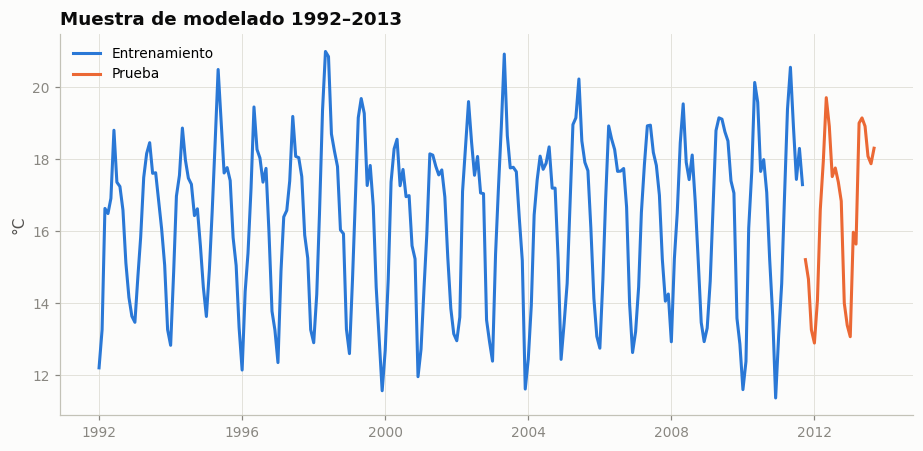

In [9]:
y = T["1992":]
train, test = tp.train_test_split_last(y, test_months=24)
print(f"Entrenamiento: {train.index.min():%Y-%m} a {train.index.max():%Y-%m} ({len(train)}) | Prueba: {test.index.min():%Y-%m} a {test.index.max():%Y-%m} ({len(test)})")

fig, ax = plt.subplots()
ax.plot(train.index, train, color=COOL, label="Entrenamiento")
ax.plot(test.index, test, color=SERIES[1], label="Prueba")
ax.set(title="Muestra de modelado 1992–2013", ylabel="°C"); ax.legend(loc="upper left")
plt.show()

In [10]:
arima_grid = tp.grid_search_sarimax(train, p=range(4), d=range(2), q=range(4))
arima_grid.head()

,order,seasonal_order,aic,bic
0,"(3, 1, 3)","(0, 0, 0, 0)",626.861,650.988
1,"(2, 1, 2)","(0, 0, 0, 0)",653.604,670.859
2,"(2, 1, 3)","(0, 0, 0, 0)",655.304,675.985
3,"(3, 1, 2)","(0, 0, 0, 0)",655.604,676.310
4,"(3, 0, 2)","(0, 0, 0, 0)",684.528,705.260


In [11]:
sarima_grid = tp.grid_search_sarimax(train, p=range(2), d=(0,), q=range(2), P=range(2), D=range(2), Q=range(2), s=12)
sarima_grid.head()

,order,seasonal_order,aic,bic
0,"(1, 0, 1)","(1, 1, 1, 12)",458.370,475.130
1,"(1, 0, 0)","(1, 1, 1, 12)",459.042,472.468
2,"(1, 0, 1)","(0, 1, 1, 12)",460.388,473.796
3,"(1, 0, 0)","(0, 1, 1, 12)",462.095,472.165
4,"(0, 0, 1)","(1, 1, 1, 12)",464.779,478.187


El AIC del mejor SARIMA es muy inferior al del mejor ARIMA: modelar explícitamente el ciclo anual domina a agregar rezagos cortos.
Criterio de parsimonia: ante AIC similares, preferir el modelo con menos parámetros.

In [12]:
best_arima, best_sarima = arima_grid.iloc[0], sarima_grid.iloc[0]
fc_arima = tp.forecast(train, len(test), best_arima.order)
fc_sarima = tp.forecast(train, len(test), best_sarima.order, best_sarima.seasonal_order)
naive = tp.seasonal_naive(train, len(test))

label_arima = f"ARIMA{best_arima.order}"
label_sarima = f"SARIMA{best_sarima.order}x{best_sarima.seasonal_order}"
metrics = pd.DataFrame({
    label_arima: tp.forecast_metrics(test, fc_arima.forecast),
    label_sarima: tp.forecast_metrics(test, fc_sarima.forecast),
    "Ingenuo estacional": tp.forecast_metrics(test, naive),
}).T
metrics["Cobertura IC95"] = [((test >= f.lower) & (test <= f.upper)).mean() for f in (fc_arima, fc_sarima)] + [np.nan]
metrics

,RMSE,MAE,Bias,Cobertura IC95
"ARIMA(3, 1, 3)",0.867,0.670,-0.109,1.000
"SARIMA(1, 0, 1)x(1, 1, 1, 12)",0.574,0.438,-0.143,0.958
Ingenuo estacional,0.963,0.731,-0.118,NaN


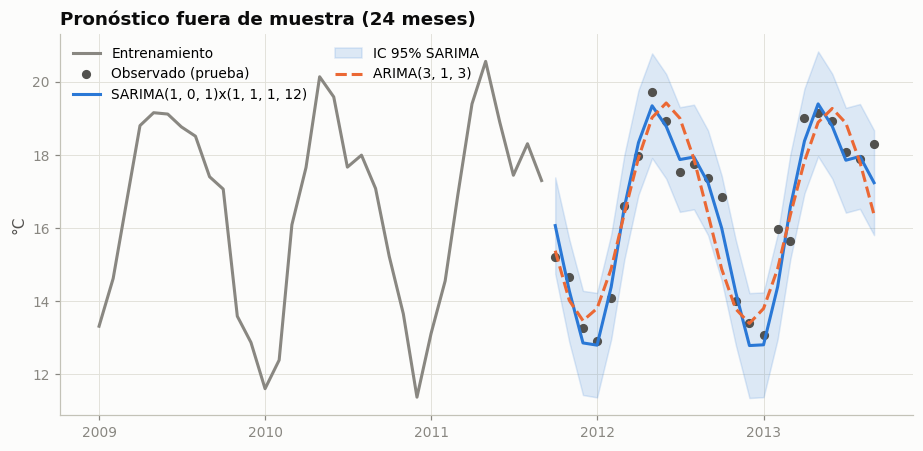

In [13]:
fig, ax = plt.subplots()
ax.plot(train["2009":].index, train["2009":], color=MUTED, label="Entrenamiento")
ax.plot(test.index, test, color=INK_2, marker="o", linewidth=0, label="Observado (prueba)")
ax.plot(fc_sarima.index, fc_sarima.forecast, color=COOL, label=label_sarima)
ax.fill_between(fc_sarima.index, fc_sarima.lower, fc_sarima.upper, color=COOL, alpha=0.15, label="IC 95% SARIMA")
ax.plot(fc_arima.index, fc_arima.forecast, color=SERIES[1], linestyle="--", label=label_arima)
ax.set(title="Pronóstico fuera de muestra (24 meses)", ylabel="°C"); ax.legend(loc="upper left", ncol=2)
plt.show()

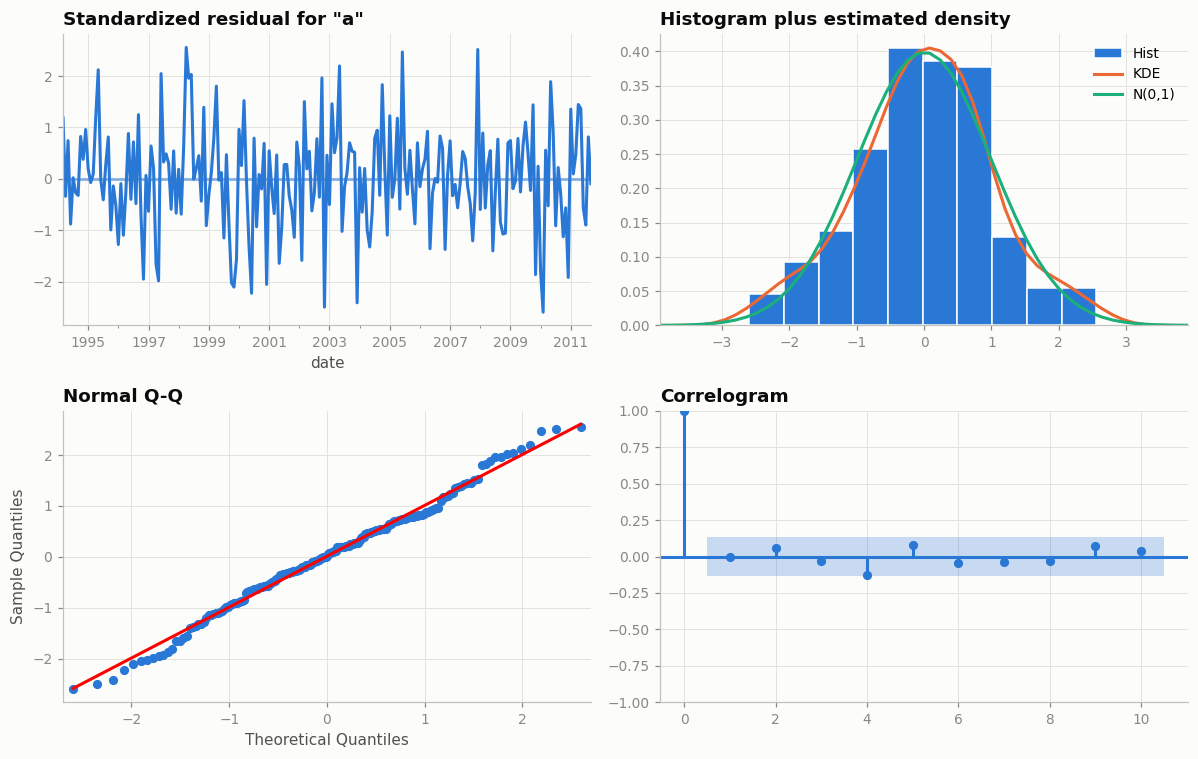

In [14]:
res = tp._fit(train, best_sarima.order, best_sarima.seasonal_order)
res.plot_diagnostics(figsize=(11, 7)); plt.tight_layout(); plt.show()

## 5. De temperatura a grados-día (HDD/CDD)

Los derivados climáticos (CME) liquidan sobre grados-día: $HDD_m=\sum_{d}\max(18-T_d,0)$, $CDD_m=\sum_d\max(T_d-18,0)$.
Con datos mensuales se aproxima con $n_m\max(18-\bar T_m,0)$. **Limitación:** subestima HDD/CDD cuando la temperatura diaria cruza la base dentro del mes; para valuar contratos se requieren datos diarios.

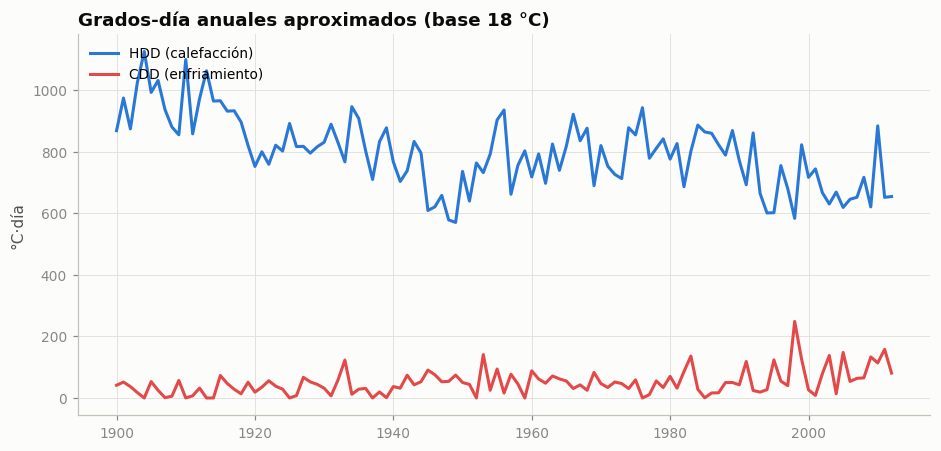

In [15]:
dd = tp.monthly_degree_days(T)
annual_dd = dd.groupby(dd.index.year).sum().loc[1900:2012]
fig, ax = plt.subplots()
ax.plot(annual_dd.index, annual_dd.HDD, color=COOL, label="HDD (calefacción)")
ax.plot(annual_dd.index, annual_dd.CDD, color=WARM, label="CDD (enfriamiento)")
ax.set(title="Grados-día anuales aproximados (base 18 °C)", ylabel="°C·día"); ax.legend(loc="upper left")
plt.show()

## Conclusiones y limitaciones

- La región muestra una tendencia de calentamiento estadísticamente significativa (ver tabla de la sección 2).
- **SARIMA** supera al ARIMA no estacional y al benchmark ingenuo fuera de muestra; su IC 95% tiene cobertura cercana a la nominal.
- Un modelo estadístico univariado **no** es un modelo climático: no incorpora forzamiento radiativo ni escenarios (SSP/NGFS). Para horizontes largos o *Climate VaR* se usan proyecciones de modelos climáticos y escenarios de transición.
- Los datos de Berkeley Earth por ciudad terminan en 2013; para análisis actuales usar ERA5 (Copernicus) o estaciones del SMN/CONAGUA.